# Activity 3: Google Trends


In this notebook you will:

1. download search terms **by hand** from the Google Trends website;
2. read and clean the file Google gives you, step by step;
3. save your terms in `raw/gtrends.csv`, the file Activity 5 uses.

In [1]:
import os

# ---- settings for this activity ----------------------------------------------
COUNTRY   = "Trinidad and Tobago"
CODE      = "TT"                          # country code, also the Google Trends geo
PATH_RAW  = os.path.join("..", "raw")     # the keyword list, and your downloads
KEYWORDS  = "TT_GTrends_Keywords.csv"     # the proposed search terms, in raw/

os.makedirs(PATH_RAW, exist_ok=True)
print(f"{COUNTRY} ({CODE})")
print("raw  :", os.path.abspath(PATH_RAW))


Trinidad and Tobago (TT)
raw  : c:\Users\guerr\Dropbox\02_Work\Consulting\2026_NWCST_CAR_Research-Workshop\trinidad\public\raw
data : c:\Users\guerr\Dropbox\02_Work\Consulting\2026_NWCST_CAR_Research-Workshop\trinidad\public\data


In [2]:
# trendspy is imported in the download cell, so Part B works without it.
import re, time, random, unicodedata, warnings
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# ---- parameters ------------------------------------------------------------
GT_START     = "2004-01-01"                         # 2004-01-01 = "all" on the website
GT_END       = date.today().strftime("%Y-%m-%d")
GT_TIMEFRAME = f"{GT_START} {GT_END}"
GT_DOWNLOAD  = False     # automatic download (end of notebook). Leave False in the workshop.
GT_PAUSE     = 5.0       # seconds between queries. Never below 2.

GT_CSV    = os.path.join(PATH_RAW, "gtrends.csv")        # what YOU download
GT_MANUAL = os.path.join(PATH_RAW, "gtrends_manual")

# Google's current month is partial: it is dropped from every save.
THIS_MONTH = pd.Timestamp(date.today()).to_period("M").to_timestamp()


def slug(s):
    """'First Citizens Bank' -> 'first_citizens_bank'."""
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]+", "_", s).strip("_")


def save(series):
    """Write a dict column -> Series to raw/gtrends.csv (zeros stored as empty)."""
    if not series:
        return None
    df = pd.DataFrame(series)
    df.index = pd.to_datetime(df.index).tz_localize(None).normalize()
    df.index.name = "date"
    df = df[~df.index.duplicated(keep="last")].sort_index()
    df = df[df.index < THIS_MONTH]
    # Trinidad's convention: a zero month is "too few searches to report", not zero.
    df = df.mask(df == 0)
    df.to_csv(GT_CSV)
    return df


print(f"period = {GT_TIMEFRAME}")

period = 2004-01-01 2026-10-25


## Step 1: the keyword list

`raw/TT_GTrends_Keywords.csv` has one row per term: the `keyword` as typed in Google,
the `geo` (country code; empty = worldwide) and the `column` name it gets in the data.
Look at the list: shopping (`amazon`, `shein`, `pricesmart`), jobs (`caribbean jobs`,
`linkedin`), banks, restaurants, tourism (`tobago hotel`, `flights trinidad` searched
**worldwide**: that is foreign demand for the country).

The `link` column opens each term in Google Trends: click a few to see what the data look like.

In [3]:
from urllib.parse import quote

def trends_link(term, geo):
    """The Google Trends page for one term, country and period."""
    period = "all" if GT_START == "2004-01-01" else f"{GT_START}%20{GT_END}"
    return (f"https://trends.google.com/trends/explore?date={period}"
            + (f"&geo={geo}" if geo else "") + f"&q={quote(term)}")

kw = pd.read_csv(os.path.join(PATH_RAW, KEYWORDS), dtype=str).fillna("")
kw["keyword"] = kw["keyword"].str.strip()
kw = kw[kw["keyword"] != ""].drop_duplicates(subset=["keyword", "geo"])
kw["link"] = [trends_link(k, g) for k, g in zip(kw["keyword"], kw["geo"])]
pd.set_option("display.max_colwidth", None)
kw

,keyword,geo,column,link
0,caribbean jobs,TT,gtrends_caribbean_jobs_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=caribbean%20jobs
1,payless,TT,gtrends_payless_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=payless
2,aldo,TT,gtrends_aldo_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=aldo
3,temu,TT,gtrends_temu_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=temu
4,shein,TT,gtrends_shein_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=shein
5,amazon,TT,gtrends_amazon_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=amazon
6,trinitrolley,TT,gtrends_trinitrolley_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=trinitrolley
7,first citizens bank,TT,gtrends_first_citizens_bank_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=first%20citizens%20bank
8,rbc,TT,gtrends_rbc_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=rbc
9,island finance,TT,gtrends_island_finance_tt,https://trends.google.com/trends/explore?date=all&geo=TT&q=island%20finance


### Exercise 1: pick your terms

Choose **one or two** terms: each is one download by hand. Take one from the list above,
and add **one term of your own** that you think tracks economic activity in Trinidad and
Tobago (a retailer, a job site, a holiday, a product...). For a new term, give `geo = "TT"`
and a column name `gtrends_<term>_tt`.

In [4]:
# Edit this list: (keyword, geo, column). Keep it to 1-2 terms.
MY_TERMS = [
    ("amazon",         "TT", "gtrends_amazon_tt"),
    ("caribbean jobs", "TT", "gtrends_caribbean_jobs_tt"),
]
print(len(MY_TERMS), "term(s) to download by hand")

2 term(s) to download by hand


## Step 2: download by hand

1. Run the next cell. It prints, for each of your terms, a Google Trends link with the right
   period (since 2004) and country.
2. Open the link. Check the chart: one term, the right country, "2004 - present".
3. Click the **download arrow** at the top right of the "Interest over time" chart.
4. Save the CSV in the folder printed below, `raw/gtrends_manual/`, **without renaming it**:
   the file name tells us the country.

In [8]:
os.makedirs(GT_MANUAL, exist_ok=True)

print(f"Save the CSVs in:\n  {GT_MANUAL}\n")
for term, geo, col in MY_TERMS:
    print(f"  {term}  ({geo or 'worldwide'})")
    print(f"    {trends_link(term, geo)}")

Save the CSVs in:
  ..\raw\gtrends_manual

  amazon  (TT)
    https://trends.google.com/trends/explore?date=all&geo=TT&q=amazon
  caribbean jobs  (TT)
    https://trends.google.com/trends/explore?date=all&geo=TT&q=caribbean%20jobs


## Step 3: look at the file

Before reading it with pandas, look at it as text: what are the columns, is there a title line,
how are the dates written?

In [10]:
import glob

files = sorted(glob.glob(os.path.join(GT_MANUAL, "*.csv")))
assert files, f"No CSV in {GT_MANUAL} yet: do Step 2 first."
for f in files:
    print(os.path.basename(f))

f = files[0]                                    # the first file
with open(f, encoding="utf-8-sig") as fh:
    print("\n" + fh.read()[:300])

multiTimeline(1).csv
multiTimeline.csv

Category: All categories

Month,caribbean jobs: (Trinidad & Tobago)
2004-01,0
2004-02,0
2004-03,0
2004-04,0
2004-05,0
2004-06,0
2004-07,0
2004-08,0
2004-09,0
2004-10,0
2004-11,0
2004-12,0
2005-01,0
2005-02,0
2005-03,0
2005-04,0
2005-05,0
2005-06,0
2005-07,0
2005-08,0
2005-09,0
2005-10,0
2005-11,0
20


## Step 4: read it with pandas

Google has used two formats. The current one (`time_series_<GEO>_....csv`) has a `Time`
column and one column named after the term. The old one (`multiTimeline.csv`) starts with
a title line, so we skip it.

In [11]:
skip = 1 if "multiTimeline" in os.path.basename(f) else 0
d = pd.read_csv(f, skiprows=skip)
d.head()

,Month,caribbean jobs: (Trinidad & Tobago)
0,2004-01,0
1,2004-02,0
2,2004-03,0
3,2004-04,0
4,2004-05,0


## Step 5: clean it

* the first column is the date, the second the term;
* Google writes `<1` for "searched, but very little": that is about 0, not missing;
* the current month is incomplete, so drop it.

In [12]:
term = d.columns[1]
d = d.rename(columns={d.columns[0]: "date", term: "value"})
d["date"]  = pd.to_datetime(d["date"])
d["value"] = pd.to_numeric(d["value"].replace("<1", 0), errors="coerce")
d = d.set_index("date")
d = d[d.index < THIS_MONTH]
print(term)
d.tail()

caribbean jobs: (Trinidad & Tobago)


,value
date,
2026-05-01,20
2026-06-01,15
2026-07-01,15
2026-08-01,13
2026-09-01,14


<Axes: title={'center': 'Google Trends: caribbean jobs: (Trinidad & Tobago)'}, xlabel='date'>

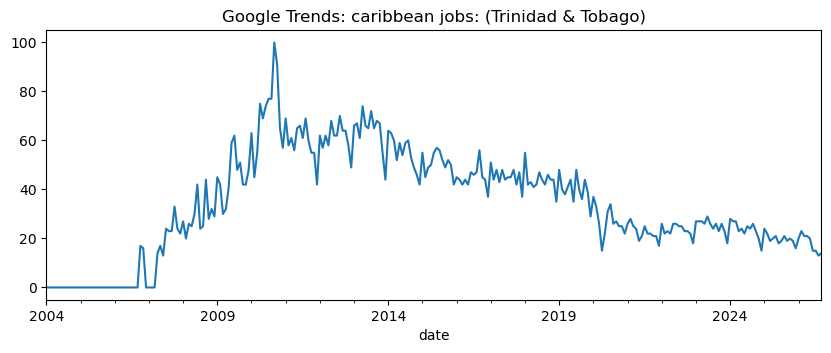

In [13]:
d.plot(figsize=(10, 3.5), title=f"Google Trends: {term}", legend=False)

## Step 6: put all your manual downloads in `raw/gtrends.csv`

The next cell does Steps 4 and 5 for every file in `raw/gtrends_manual/`, in both formats:

| file | format |
|---|---|
| `multiTimeline*.csv` | old page: a title line, then `Month`, `term: (Country)` |
| `time_series_<GEO>_*.csv` | current page: `Time` and the term |

Each column takes the `column` name of its term in `MY_TERMS` (or in the keyword list), so a
manual series lands exactly where an automatic download would.

In [14]:
lookup = {slug(t): c for t, g, c in MY_TERMS}
lookup.update({slug(k): c for k, c in zip(kw["keyword"], kw["column"]) if slug(k) not in lookup})

def target_column(term, geo):
    return lookup.get(slug(term), "gtrends_" + slug(term) + "_" + (geo.lower() or "worldwide"))

pieces = []
for f in sorted(glob.glob(os.path.join(GT_MANUAL, "*ultiTimeline*.csv"))):
    d = pd.read_csv(f, skiprows=1).rename(columns={"Month": "date"})
    for c in d.columns[1:]:
        m = re.match(r"(.*?):\s*\((.*)\)\s*$", str(c))
        term, place = (m.group(1), m.group(2)) if m else (str(c), "")
        geo = "" if place.lower() == "worldwide" else CODE
        pieces.append(d.set_index("date")[c].rename(target_column(term, geo)))
for f in sorted(glob.glob(os.path.join(GT_MANUAL, "time_series_*.csv"))):
    m = re.match(r"time_series_([A-Za-z]+)_", os.path.basename(f))
    geo = m.group(1).upper() if m else ""
    geo = "" if geo in ("GLB", "WORLDWIDE", "WW") else geo
    d = pd.read_csv(f).rename(columns={"Time": "date"})
    for c in d.columns[1:]:
        pieces.append(d.set_index("date")[c].rename(target_column(c, geo)))

if not pieces:
    print("No manual files in raw/gtrends_manual/.")
else:
    manual = pd.concat(pieces, axis=1)
    manual.index = pd.to_datetime(manual.index, errors="coerce")
    manual = manual[manual.index.notna()]
    manual = manual.loc[:, ~manual.columns.duplicated(keep="last")]
    # Google writes "<1" for minimal interest: that is ~0, not missing
    manual = manual.replace("<1", 0).apply(pd.to_numeric, errors="coerce")
    series = ({c: s for c, s in pd.read_csv(GT_CSV, index_col="date", parse_dates=["date"]).items()}
              if os.path.exists(GT_CSV) else {})
    series.update({c: manual[c] for c in manual.columns})
    out = save(series)
    print(f"-> {GT_CSV}: {out.shape[1]} series, {out.index.min().date()} to {out.index.max().date()}")
    print("merged:", list(manual.columns))

-> ..\raw\gtrends.csv: 2 series, 2004-01-01 to 2026-09-01
merged: ['gtrends_caribbean_jobs_tt', 'gtrends_amazon_tt']


In [16]:
out

,gtrends_caribbean_jobs_tt,gtrends_amazon_tt
date,,
2004-01-01,NaN,NaN
2004-02-01,NaN,NaN
2004-03-01,NaN,NaN
2004-04-01,NaN,NaN
2004-05-01,NaN,9.0
...,...,...
2026-05-01,20.0,27.0
2026-06-01,15.0,28.0
2026-07-01,15.0,28.0


---

# Appendix: the automatic download (switched off)

This is how the instructors download the full set of terms: one query per term with `trendspy`, a pause between
queries, and the file saved after every term. It only runs if you set `GT_DOWNLOAD = True` in
the parameters cell. **Leave it off in the workshop**: we all share one internet address.

`pytrends`, the library most old notebooks use, was archived on 2025-04-17 and now fails with
`429 Too Many Requests` on the first call. `trendspy` is a maintained replacement (no API key).

In [ ]:
if not GT_DOWNLOAD:
    print("Automatic download switched off (GT_DOWNLOAD = False). Use the manual download above.")
else:
    from trendspy import Trends              # if missing:  pip install trendspy

    assert len(MY_TERMS) <= 5, "Keep it to a handful of terms; we share one IP address."

    tr = Trends(request_delay=max(GT_PAUSE, 2.0))
    series = ({c: s for c, s in pd.read_csv(GT_CSV, index_col="date", parse_dates=["date"]).items()}
              if os.path.exists(GT_CSV) else {})
    failed = []

    for i, (term, geo, col) in enumerate(MY_TERMS, 1):
        tr.request_delay = random.uniform(GT_PAUSE, GT_PAUSE + 1.0)
        try:
            d = tr.interest_over_time([term], geo=geo, timeframe=GT_TIMEFRAME)
            c = [c for c in d.columns if c != "isPartial"][0]
            s = pd.to_numeric(d[c], errors="coerce")
            s.index = pd.to_datetime(d.index).tz_localize(None).normalize()
            series[col] = s
            save(series)                                # <- saved after every term
            print(f"  [{i}/{len(MY_TERMS)}] {term:20} ok  ({(s > 0).mean():.0%} non-zero months)")
        except Exception as e:
            failed.append(term)
            print(f"  [{i}/{len(MY_TERMS)}] {term:20} !! {type(e).__name__}: {str(e)[:80]}")
            if "429" in str(e) or "Too Many" in str(e):
                print("      Google rate limit. Use the manual download above.")
                break

    mine = save(series)
    if mine is not None:
        print(f"\nraw/gtrends.csv: {mine.shape[1]} series, "
              f"{mine.index.min().date()} to {mine.index.max().date()}")